## I. Load data

In [168]:
import pandas as pd
import os
from nltk.corpus import stopwords

In [2]:
df_tweets_replies_perfil_lula = pd.read_parquet('/home/kaka/tcc/ml/samples/tweets-replies-2022_10_10-perfil_lula.parquet')
df_quotes_perfil_lula = pd.read_parquet('/home/kaka/tcc/ml/samples/tweets-quotes-2022_10_10-perfil_lula.parquet')
df_tweets_query_bolsonaro = pd.read_parquet('/home/kaka/tcc/ml/samples/tweets-2022_10_10-query_bolsonaro.parquet')
df_tweets_perfil_lula = pd.read_parquet('/home/kaka/tcc/ml/samples/tweets-2022_10_10-perfil_lula.parquet')
df_tweets_query_lula = pd.read_parquet('/home/kaka/tcc/ml/samples/tweets-2022_10_10-query_lula.parquet')


### visualize first rows from each data frame

In [3]:
df_tweets_replies_perfil_lula.head()

In [ ]:
df_quotes_perfil_lula.head()

In [ ]:
df_tweets_query_bolsonaro.head()


In [ ]:
df_tweets_perfil_lula.head()

In [ ]:
df_tweets_query_lula.head()

In [5]:
lula_df = pd.concat([df_tweets_replies_perfil_lula, df_quotes_perfil_lula, df_tweets_query_lula, df_tweets_perfil_lula])
lula_df.drop_duplicates(subset=['text'], inplace=True)

### merge dfs 

In [ ]:
df = pd.concat([df_tweets_replies_perfil_lula, df_quotes_perfil_lula, df_tweets_query_bolsonaro, df_tweets_perfil_lula, df_tweets_query_lula])

In [ ]:
import pandas as pd

df = pd.read_parquet('tweets.parquet')

In [ ]:
import unicodedata

df.drop_duplicates(subset='text', keep='first', inplace=True)

# remove garbage from text
df['text'] = df['text'].str.replace(r"@\S+", " ", regex=True).str.strip() 
df['text'] = df['text'].str.lower()
df['text'] = df['text'].str.replace(r"http\S+", " ", regex=True).str.strip()
df['text'] = df['text'].str.replace(r"https\S+", " ", regex=True).str.strip() 
df['text'] = df['text'].str.replace(r"\n", " ", regex=True).str.strip() 
df['text'] = df['text'].str.replace(r"\s+", " ", regex=True).str.strip() # remove multiple spaces

# remove punctuation
df['text'] = df['text'].str.replace(r"[^\w\s]", " ", regex=True).str.strip()

stop_words = set(stopwords.words('portuguese'))
df['text'] = df['text'].apply(lambda x: ' '.join([word for word in x.split() if word not in (stop_words)]))
df.drop_duplicates(subset='text', keep='first', inplace=True)
#df['text'] = df['text'].apply(lambda x: ' '.join([word for word in x.split() if word not in (words_to_remove)]))

stop_words_normalized = set([unicodedata.normalize('NFKD', word).encode('ascii', errors='ignore').decode('utf-8') for word in stop_words])
df['text'] = df['text'].apply(lambda x: ' '.join([word for word in x.split() if word not in (stop_words_normalized)]))
df['text'] = df['text'].str.replace(r"[^\w\s]", " ", regex=True).str.strip() 

## remove accents from text
df['text'] = df['text'].apply(lambda x: unicodedata.normalize('NFD', x).encode('ascii', errors='ignore').decode('utf-8'))

df.drop_duplicates(subset='text', keep='first', inplace=True)


In [1]:
import pandas as pd 

df = pd.read_parquet('original_df.parquet')

findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica, Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica, Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica, Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica, Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica, Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica, Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica, Arial
findfont: Generic family 'sans-serif' not found because none of the following families were found: Helvetica, Arial
findfont: Generic family 'sans-serif' not found because none of the foll

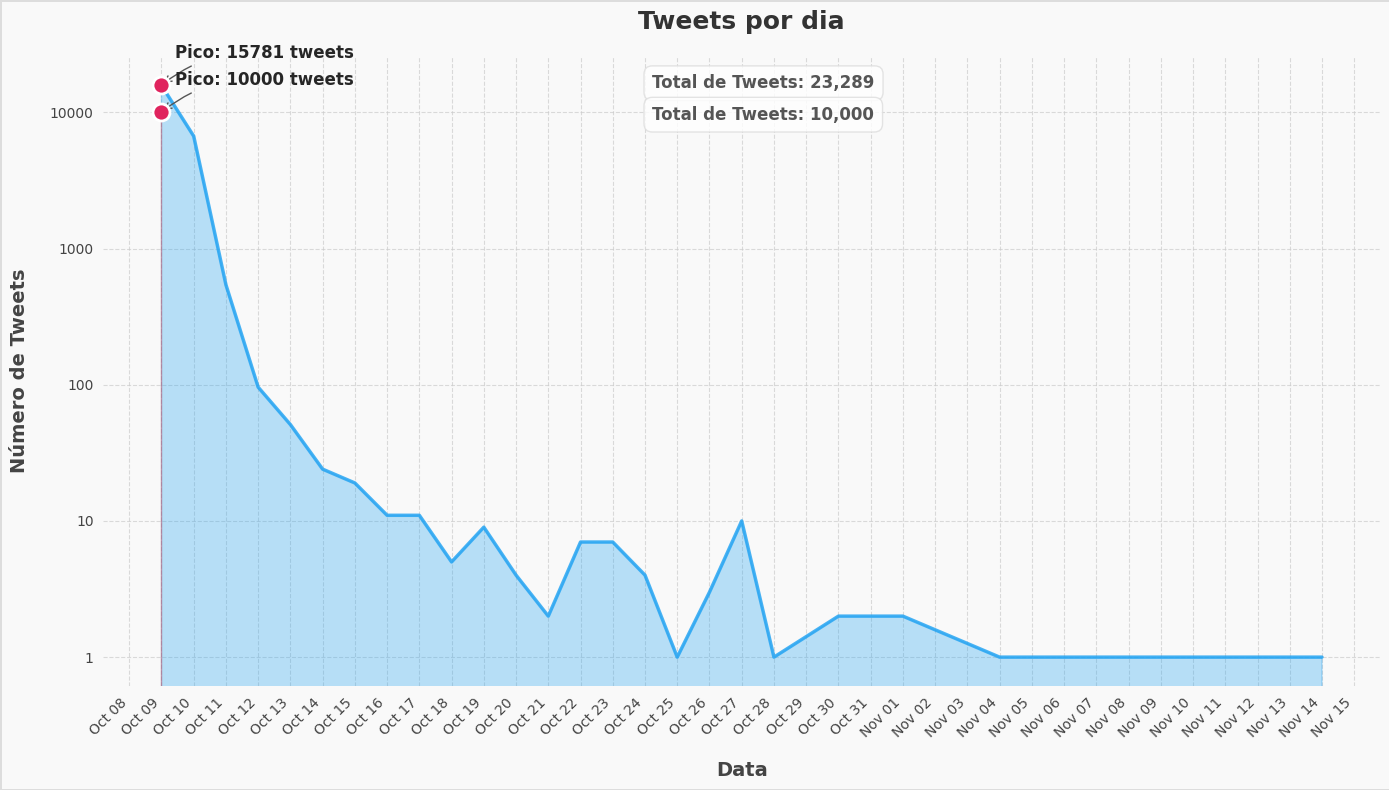

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
import numpy as np
from matplotlib.ticker import MaxNLocator

sns.set_style("whitegrid")
plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = ['Helvetica', 'Arial']

df['created_at'] = pd.to_datetime(df['created_at'])


tweets_per_day = df.resample('D', on='created_at').size()
tweets_per_day = tweets_per_day[tweets_per_day > 0]


plot_df = tweets_per_day.reset_index()
plot_df.columns = ['Date', 'Tweets']

fig, ax = plt.subplots(figsize=(14, 8), dpi=100, facecolor='#f9f9f9')

ax.set_facecolor('#f9f9f9')

main_color = '#1DA1F2'  # Twitter blue
ax.fill_between(plot_df['Date'], plot_df['Tweets'], alpha=0.3, color=main_color)
ax.plot(plot_df['Date'], plot_df['Tweets'], color=main_color, linewidth=2.5, alpha=0.8)



peak_idx = plot_df['Tweets'].idxmax()
peak_date = plot_df.loc[peak_idx, 'Date']
peak_count = plot_df.loc[peak_idx, 'Tweets']
ax.scatter(peak_date, peak_count, s=150, color='#E0245E', edgecolor='white', linewidth=2, zorder=5)
ax.annotate(f'Pico: {peak_count} tweets', (peak_date, peak_count),
            xytext=(10, 20), textcoords='offset points', 
            fontsize=12, fontweight='bold',
            arrowprops=dict(arrowstyle='->', connectionstyle='arc3,rad=.2', color='#555555'))


ax.xaxis.set_major_locator(mdates.DayLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))


ax.grid(True, linestyle='--', alpha=0.7, color='#CCCCCC')


ax.set_xlabel('Data', fontsize=14, fontweight='bold', labelpad=15, color='#444444')
ax.set_ylabel('Número de Tweets', fontsize=14, fontweight='bold', labelpad=15, color='#444444')
ax.set_title('Tweets por dia', fontsize=18, fontweight='bold', pad=20, color='#333333')

total_tweets = plot_df['Tweets'].sum()
ax.text(0.43, 0.95, f'Total de Tweets: {total_tweets:,}', transform=ax.transAxes, 
        fontsize=12, fontweight='bold', color='#555555',
        bbox=dict(facecolor='white', alpha=0.8, boxstyle='round,pad=0.5', edgecolor='#DDDDDD'))


plt.xticks(rotation=45, ha='right', color='#444444', fontsize=10)
plt.yticks(color='#444444')

# Usar escala logarítmica 
ax.set_yscale('log')
from matplotlib.ticker import ScalarFormatter
ax.yaxis.set_major_formatter(ScalarFormatter())

for spine in ax.spines.values():
    spine.set_visible(False)

fig.patch.set_linewidth(2)
fig.patch.set_edgecolor('#DDDDDD')

plt.tight_layout()
plt.show()


In [ ]:
# number of tweets per day 
tweets_per_day = df.resample('D', on='created_at').size()
# get only days that have at least 1 tweet
tweets_per_day = tweets_per_day[tweets_per_day > 0]
tweets_per_day


In [ ]:

# get count of days with at least 1 tweet
days_with_tweets = len(tweets_per_day)

days_with_tweets

In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 34217 entries, 0 to 9999
Data columns (total 19 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   column_0             34217 non-null  float64
 1   id                   34217 non-null  object 
 2   text                 34217 non-null  object 
 3   created_at           34217 non-null  object 
 4   source               34217 non-null  object 
 5   lang                 34217 non-null  object 
 6   conversation_id      34217 non-null  object 
 7   like_count           34217 non-null  object 
 8   retweet_count        34217 non-null  object 
 9   quote_count          34217 non-null  object 
 10  reply_count          34217 non-null  object 
 11  type                 34217 non-null  object 
 12  referenced_tweet_id  29885 non-null  object 
 13  mentions             24585 non-null  object 
 14  hashtags             2352 non-null   object 
 15  urls                 13083 non-null  objec

In [ ]:
# Engajamento 

df[['like_count', 'retweet_count', 'quote_count', 'reply_count']] = df[
    ['like_count', 'retweet_count', 'quote_count', 'reply_count']
].apply(pd.to_numeric, errors='coerce')

# Fill NaN values with 0 (in case there are missing values)
df.fillna({'like_count': 0, 'retweet_count': 0, 'quote_count': 0, 'reply_count': 0}, inplace=True)

# Create engagement score
df["engagement_score"] = df["like_count"] + df["retweet_count"] + df["quote_count"] + df["reply_count"]

# Get the top 10 tweets with highest engagement
top_tweets = df.sort_values(by="engagement_score", ascending=False).head(3500)

# Display the top tweets (columns: id, text, engagement_score)
print(top_tweets[['id', 'text', 'engagement_score']])


In [ ]:

from collections import Counter 

split_it = top_tweets['text'].str.split()
Counter = Counter(split_it.apply(pd.Series).stack())

words_to_remove = {"vem", "dizer", "mesma", "precisa", "caso", "meno", "tava", "tbm", "porque", "apena", "deveria", "quanto", "junto", "falar", "sendo", "gerais", "enquanto", "sabe", "quero","queria", "vi", "acho", "to", "disse", "falou", "ver", "agora", "volta", "alguém", "bom", "deve", "nesse", "vamo", "pode", "gerai", "toda", "ter", "via", "sei", "então", "tanto", "ver", "melhor", "certeza", "fazendo", "vez", "disso", "nele", "queria", "sei", "pode", 'vai', 'pra', 'vc', 'q', 'tá', 'aí', 'aqui', 'fazer', 'fez', 'pq', 'faz', 'pro', 'né', 'lá', 'vcs', 'fala', 'assim', 'vou', 'olha', 'dar', 'tão', 'diz', 'kkkk', 'kkkkk', 'vão', 'desse', 'n', '2', '4', 'kkkkkk', 'ai', 'p', 'dessa', 'viu', 'ir', 'dá'}
top_tweets['text'] = top_tweets['text'].apply(lambda x: ' '.join([word for word in x.split() if word not in (words_to_remove)]))
most_occur_corr = Counter.most_common(200)


In [ ]:
%pip install seaborn
import seaborn as sns
import matplotlib.pyplot as plt

# Compute the correlation matrix
engagement_metrics = ['like_count', 'retweet_count', 'quote_count', 'reply_count']
corr_matrix = df[engagement_metrics].corr()

# Plot the heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap="YlOrRd", fmt=".2f", linewidths=0.5)

plt.title("Correlação entre as métricas de engajamento")
plt.show()


## II. Preprocessing data

In [ ]:
df = df.drop_duplicates(subset='text', keep='first')

# useful columns id, text, hashtags, author_id, conversation_id, referenced_tweet_id, mentions
# removing hashtag column because 90% of the values are null
df = df[['id', 'text', 'author_id', 'conversation_id', 'like_count', 'retweet_count', 'quote_count','reply_count', 'referenced_tweet_id', 'mentions']]

df.isnull().sum()

df = df.drop_duplicates(subset='text', keep='first')
df.info()


In [ ]:
from collections import Counter 

split_it = df['text'].str.split()
Counter = Counter(split_it.apply(pd.Series).stack())

most_occur = Counter.most_common(200)

words_to_remove = ['vai', 'pra', 'vc', 'q', 'tá', 'aí', 'aqui', 'fazer', 'fez', 'pq', 'faz', 'pro', 'né', 'lá', 'vcs', 'fala', 'assim', 'vou', 'olha', 'dar', 'tão', 'diz', 'kkkk', 'kkkkk', 'vão', 'desse', 'n', '2', '4', 'kkkkkk', 'ai', 'p', 'dessa', 'viu', 'ir', '1', 'dá']

In [ ]:
import unicodedata

# remove garbage from text
df['text'] = df['text'].str.replace(r"@\S+", " ", regex=True).str.strip() 
df['text'] = df['text'].str.lower()
df['text'] = df['text'].str.replace(r"http\S+", " ", regex=True).str.strip()
df['text'] = df['text'].str.replace(r"https\S+", " ", regex=True).str.strip() 
df['text'] = df['text'].str.replace(r"\n", " ", regex=True).str.strip() 
df['text'] = df['text'].str.replace(r"\s+", " ", regex=True).str.strip() # remove multiple spaces

# remove punctuation
df['text'] = df['text'].str.replace(r"[^\w\s]", " ", regex=True).str.strip()

stop_words = set(stopwords.words('portuguese'))
df['text'] = df['text'].apply(lambda x: ' '.join([word for word in x.split() if word not in (stop_words)]))
df.drop_duplicates(subset='text', keep='first', inplace=True)
df['text'] = df['text'].apply(lambda x: ' '.join([word for word in x.split() if word not in (words_to_remove)]))
df.drop_duplicates(subset='text', keep='first', inplace=True)

stop_words_normalized = set([unicodedata.normalize('NFKD', word).encode('ascii', errors='ignore').decode('utf-8') for word in stop_words])
df['text'] = df['text'].apply(lambda x: ' '.join([word for word in x.split() if word not in (stop_words_normalized)]))
df['text'] = df['text'].str.replace(r"[^\w\s]", " ", regex=True).str.strip() 

## remove accents from text
df['text'] = df['text'].apply(lambda x: unicodedata.normalize('NFD', x).encode('ascii', errors='ignore').decode('utf-8'))

df = df[['id', 'text']]
df.drop_duplicates(subset='text', keep='first', inplace=True)
df['label'] = -1
df.info()
df.to_parquet('clean_tweets.parquet')

## Clusters

In [ ]:
import pandas as pd 
df = pd.read_parquet('clean_tweets.parquet')

In [ ]:
df.head()

In [ ]:
# get clusters from tweets

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.cluster import KMeans

vectorizer = TfidfVectorizer()
X = vectorizer.fit_transform(df['text'])

true_k = 14

model = KMeans(n_clusters=true_k, init='k-means++', max_iter=100, n_init=1)
model.fit(X)

order_centroids = model.cluster_centers_.argsort()[:, ::-1]
terms = vectorizer.get_feature_names_out()
for i in range(true_k):
    print("Cluster %d:" % i),
    for ind in order_centroids[i, :10]:
        print(' %s' % terms[ind])
    print()


------- end of draft

## Analysis of the data

### First attempt to manually labeling. 45 tweets were labeled. 

for this, the data was sorted based on 'likes_count' column in descending order. 

In [ ]:
# 0 - true | 1 - false

ids_true = [
    "1579094370275717120",
    "1579247094312812544",
    "1579249308507189249",
    "1579257152610668546",
    "1579258077697937408",
    "1579253412067102721",
    "1579257077062864896",
    "1579246648542101505",
    "1579260081153404928",
    "1579189927132397568",
    "1579248875172376576",
    "1579246754616123393",
    "1579148185632927744",
    "1579183600008060929",
    "1579252515669180416",
    "1579256593254092800",
    "1579183224701394944",
    "1579254320192581632",
    "1579178100449243144",
    "1579172239450468352",
    "1579246202369241089",
    "1579245328527671296",
    "1579250518794260481",
    "1579256081347678211",
    "1579231266284900352",
    "1579246210782621696",
    "1579177461111488512",
    "1579331819685965824",
    "1579250672868167680",
    "1579258494423019520",
    "1579249085600497665"
]

ids_fake = [
    "1579250775188213760",
    "1579253779991769089",
    "1579252176274489345",
    "1579255923742507008",
    "1579256967675392000",
    "1579250339173531648",
    "1579251877661003781",
    "1579253161658789888",
    "1579258227816304641",
    "1579255507118100480",
    "1579254907265130496",
    "1579253466937102338",
    "1579255896169156609",
    "1579258978269552641",
    "1579246516543553538",
    "1579253660860977152",
    "1579258250406793217",
    "1579245821328904192",
    "1579256575218176000"
]

df.loc[df['id'].isin(ids_true), 'label'] = 0
df.loc[df['id'].isin(ids_fake), 'label'] = 1

df.to_parquet('clean_tweets.parquet')

df_labeled = df.loc[df['label'] != -1]

# Display the filtered DataFrame
df_labeled


In [ ]:
df_original = pd.read_parquet('tweets.parquet')
# df_original['like_count'] = df_original['like_count'].astype(int)
# df_original.sort_values(by='like_count', ascending=False, inplace=True)

## III. [WIP] Training Model

Splitting our dataset into train and test. Here we are working only with the values who weren't labelled. 

In [83]:
import pandas as pd
df = pd.read_parquet('data/clean_tweets.parquet')
#df = pd.read_csv('data/low_confidence_ml.csv')

In [84]:
from sklearn.model_selection import train_test_split
import numpy as np

df_unlabeled = df[df['label'] == -1]

# df_unlabeled_train, df_unlabeled_test = train_test_split(df_unlabeled, test_size=0.2, random_state=42)
df_train, df_test = train_test_split(df, test_size=0.2, random_state=42)

In [85]:
# class labels for training
ABSTAIN = -1
TRUE = 0
FAKE = 1

### Creating labeling functions to 'FAKE' label

no momento, existem 15 lfs ao total

In [86]:
from snorkel.labeling import labeling_function

canibal_keywords = ['canibal', 'canibalismo', 'carne humana']
maconaria_keywords = ['maconaria', 'macom', 'seita']
satanismo_keywords = ['satanismo', 'satanista', 'satanico','baphomet']
censura_keywords = ['censura', 'censurar', 'censurado']
pcc_keywords = ['pcc', 'marcola']
ameaca_keywords = ['ameaca', 'ameacar', 'ameacado', 'ameacando', 'ameacou']
aborto_keywords = ['aborto', 'abortar', 'abortista']
comunismo_keywords = ['comunismo', 'comunista', 'mst']
taxacao_keywords = ['taxacao', 'taxar', 'taxado', 'taxando', 'taxou']
lula_keywords = ['nine', '9 dedos', 'cachaceiro']
pedofilia_keywords = ['pedofilia', 'pedofilo', 'pedofilos'] 
zema_keywords = ['zema', 'romeu zema', 'mg', 'governador', 'minas gerais']
corrupto_keywords = ['ladrao', 'corrupto', 'corrupcao', 'corrupcao', 'ladroes']
@labeling_function(resources=dict(canibal_keywords=canibal_keywords))
def keyword_canibal(x, canibal_keywords):
    return FAKE if any(word in x.text.lower() for word in canibal_keywords) else ABSTAIN
@labeling_function(resources=dict(maconaria_keywords=maconaria_keywords))
def keyword_maconaria(x, maconaria_keywords):
    return FAKE if any(word in x.text.lower() for word in maconaria_keywords) else ABSTAIN
@labeling_function(resources=dict(satanismo_keywords=satanismo_keywords))
def keyword_satanismo(x, satanismo_keywords):
    return FAKE if any(word in x.text.lower() for word in satanismo_keywords) else ABSTAIN
@labeling_function(resources=dict(censura_keywords=censura_keywords))
def keyword_censura(x, censura_keywords):
    return FAKE if any(word in x.text.lower() for word in censura_keywords) else ABSTAIN
@labeling_function(resources=dict(pcc_keywords=pcc_keywords))
def keyword_pcc(x, pcc_keywords):
    return FAKE if any(word in x.text.lower() for word in pcc_keywords) else ABSTAIN
@labeling_function(resources=dict(ameaca_keywords=ameaca_keywords))
def keyword_ameaca(x, ameaca_keywords):
    return FAKE if any(word in x.text.lower() for word in ameaca_keywords) else ABSTAIN
@labeling_function(resources=dict(zema_keywords=zema_keywords))
def keyword_zema(x, zema_keywords):
    return FAKE if any(word in x.text.lower() for word in zema_keywords) else ABSTAIN
@labeling_function()
def lf_rouanet(x):
    return FAKE if 'rouanet' in x.text.lower() else ABSTAIN
@labeling_function(resources=dict(aborto_keywords=aborto_keywords))
def keyword_aborto(x, aborto_keywords):
    return FAKE if any(word in x.text.lower() for word in aborto_keywords) else ABSTAIN
@labeling_function(resources=dict(comunismo_keywords=comunismo_keywords))
def keyword_comunismo(x, comunismo_keywords):
    return FAKE if any(word in x.text.lower() for word in comunismo_keywords) else ABSTAIN
@labeling_function()
def lf_rouanet(x):
    return FAKE if 'rouanet' in x.text.lower() else ABSTAIN
@labeling_function()
def lf_fraude_em_urnas(x):
    return FAKE if ('fraude' and ('urna' or 'urnas')) in x.text.lower() else ABSTAIN
@labeling_function(resources=dict(taxacao_keywords=taxacao_keywords))
def lf_taxacao(x, taxacao_keywords):
    return FAKE if any(word in x.text.lower() for word in taxacao_keywords) else ABSTAIN
@labeling_function()
def lf_pedofilia(x):
    return FAKE if 'pedofilia' in x.text.lower() else ABSTAIN
@labeling_function(resources=dict(corrupto_keywords=corrupto_keywords))
def lf_ladrao(x, corrupto_keywords):
    return FAKE if any(word in x.text.lower() for word in corrupto_keywords) else ABSTAIN
@labeling_function(resources=dict(lula_keywords=lula_keywords))
def keyword_lula(x, lula_keywords):
    return FAKE if any(word in x.text.lower() for word in lula_keywords) else ABSTAIN

### Creating labeling functions to 'TRUE' label

Por agora, foram considerados sem fake news tweets onde não há noticias falsas, no geral. 

Por exemplo: declaração de voto e opiniões livres que nao contem fake news. 

In [87]:
declaracao_voto_keywords = ['lula13', 'bolsonaro22', 'lula presidente', 'bolsonaro presidente', 'lula 2022', 'bolsonaro 2022']

@labeling_function(resources=dict(declaracao_voto_keywords=declaracao_voto_keywords))
def keyword_declaracao_voto(x, declaracao_voto_keywords):
    return TRUE if any(word in x.text for word in declaracao_voto_keywords) else ABSTAIN

### Applying LFs

In [70]:
from snorkel.labeling import PandasLFApplier

lfs = [keyword_canibal, keyword_maconaria, keyword_satanismo, keyword_censura, keyword_pcc, keyword_ameaca, keyword_zema, lf_rouanet, keyword_aborto, keyword_declaracao_voto, keyword_comunismo, lf_fraude_em_urnas, lf_taxacao, lf_pedofilia, lf_ladrao, keyword_lula]

applier = PandasLFApplier(lfs=lfs)


In [88]:
L_train = applier.apply(df=df_train)

100%|██████████| 21967/21967 [00:06<00:00, 3357.01it/s]


In [89]:
from snorkel.labeling import LFAnalysis

LFAnalysis(L=L_train, lfs=lfs).lf_summary()

,j,Polarity,Coverage,Overlaps,Conflicts
keyword_canibal,0,[1],0.010516,0.003005,0.000319
keyword_maconaria,1,[1],0.002640,0.000910,0.000000
keyword_satanismo,2,[1],0.003414,0.001548,0.000046
keyword_censura,3,[1],0.004006,0.001184,0.000046
keyword_pcc,4,[1],0.006237,0.001775,0.000046
keyword_ameaca,5,[1],0.018619,0.012519,0.000182
keyword_zema,6,[1],0.040834,0.015068,0.001821
lf_rouanet,7,[1],0.004461,0.000319,0.000046
keyword_aborto,8,[1],0.004734,0.001775,0.000046
keyword_declaracao_voto,9,[0],0.020394,0.003642,0.003642


In [90]:
from snorkel.labeling.model import LabelModel


label_model = LabelModel(cardinality=2, verbose=True)
label_model.fit(L_train, n_epochs=65, log_freq=10, seed=123)

INFO:root:Computing O...
INFO:root:Estimating \mu...
  0%|          | 0/65 [00:00<?, ?epoch/s]INFO:root:[0 epochs]: TRAIN:[loss=0.003]
INFO:root:[10 epochs]: TRAIN:[loss=0.001]
INFO:root:[20 epochs]: TRAIN:[loss=0.000]
INFO:root:[30 epochs]: TRAIN:[loss=0.000]
INFO:root:[40 epochs]: TRAIN:[loss=0.000]
INFO:root:[50 epochs]: TRAIN:[loss=0.000]
INFO:root:[60 epochs]: TRAIN:[loss=0.000]
100%|██████████| 65/65 [00:00<00:00, 742.32epoch/s]
INFO:root:Finished Training


In [100]:
y_preds = label_model.predict(L=L_train)  # predict with probabilities
df_train.loc[:, 'label'] = y_preds # 

In [101]:
y_preds.shape

(21967,)

In [98]:
from snorkel.analysis import get_label_buckets

buckets = get_label_buckets(L_train[:, 0], L_train[:, 2])
df_unlabeled.iloc[buckets[(FAKE, ABSTAIN)]].sample(10, random_state=1)

,id,text,label
9740,1579430305592934402,imagem montada fake news,-1
3297,1579492255622389761,podemos chamar geni,-1
803,1579219057727131648,caliquinha,-1
2564,1579256163669266432,fato grande erro achar instituicoes segurar de...,-1
9515,1579457209804943364,pouca gente mostraria mostrando imagens alto p...,-1
503,1579244195394752512,ah vagabundo vive paris deveria mudar cuba ven...,-1
6704,1579424382619111430,esperanca brasil pt loola cadeia mtst invadind...,-1
3926,1579303011171860480,assista video razao emocao,-1
9551,1579454458416988161,rua ambiente fechado,-1
467,1579612459752914947,melhor corrupcao,-1


### Removendo dados não rotulados

In [102]:
from snorkel.labeling import filter_unlabeled_dataframe

df_unlabeled_filtered, probs = filter_unlabeled_dataframe(df_train, y_preds, L_train)

df_unlabeled_filtered['label'].value_counts()

label
1    3970
0     369
Name: count, dtype: int64

In [103]:
int(df_unlabeled_filtered['label'].value_counts().sum())

4339

Get tweets with low confidence

In [21]:
confidence_scores = label_model.predict_proba(L=L_train)  # get confidence scores

In [29]:
# Altere esta linha: extrair a maior probabilidade para cada exemplo
class_confidences = np.max(confidence_scores, axis=1)

# O restante do código permanece igual
# Add confidence scores to the dataframe
df_unlabeled.loc[:, 'confidence'] = class_confidences

# Filter the data where confidence score is below 76%
filtered_data = df_unlabeled[(df_unlabeled['confidence'] < 0.75) & (df_unlabeled['label'] != -1)].copy()

# Display the filtered data
filtered_data


,id,text,label,confidence
2,1579957163543629824,pretende votar lula assista documentario tire ...,1,0.747627
10,1579619756055093248,l ladrao vote 22 bolsonaro,1,0.747627
17,1579593903283765248,corrupto,1,0.747627
21,1579581726682419201,maior ladrao brasil chega disso olhar foto medo,1,0.747627
34,1579530877650235393,foraluladrao,1,0.747627
...,...,...,...,...
9969,1579244929418551299,pior luladrao manda homem bater mulher casa,1,0.747627
9972,1579244925505662977,luladrao falar bobagens,1,0.747627
9986,1579244894551363584,podem liberar bilhao brasileiro comprado luladrao,1,0.747627
9988,1579244891237806080,voto luladrao,1,0.747627


In [28]:
ids_low_confidence = filtered_data['id'].tolist() 

In [ ]:
# from tweets.parquet, get only the tweets filter by ids_low_confidence

df_low_confidence = df_original.loc[df_original['id'].isin(ids_low_confidence)]
df_low_confidence = df_low_confidence[['id', 'text']]
df_low_confidence.rename(columns={'id': 'tweet_id'}, inplace=True)
df_low_confidence['text'] = df_low_confidence['text'].str.replace(r"http\S+", " ", regex=True).str.strip().str.replace(r"https\S+", " ", regex=True).str.strip().copy()


In [ ]:
df_low_confidence.head()


In [ ]:
df_low_confidence.info()

In [ ]:
# size = len(df_low_confidence)
# batch = size // 35
# batch

In [ ]:
# # batch to save in json files 
# for i in range(0, size, batch):
#     df_low_confidence.iloc[i:i+batch].to_json(f'low_confidence_tweets/low_confidence_{i}.json', orient='records')

# # ver como salvar os tweets no mongodb

## retraining model

In [55]:
import pandas as pd 
low_confidence = pd.read_csv('low_confidence_ml.csv')

In [56]:
#filtered_data.to_csv('low_confidence_ml.csv', index=False)
low_confidence

,id,text,label,confidence
0,1579957163543629824,pretende votar lula assista documentario tire ...,1,0.251934
1,1579619756055093248,l ladrao vote 22 bolsonaro,1,0.251934
2,1579581726682419201,maior ladrao brasil chega disso olhar foto medo,1,0.251934
3,1579568677657067521,devemos sempre ressaltar cristao nunca pode ap...,1,0.243433
4,1579531987253342208,lkkkkkkkkkkk todos 22 massacrado urnas ladrao,1,0.102408
...,...,...,...,...
3508,1579244896749498369,grande coisa maior traficante pais bota lula v...,1,0.238559
3509,1579244894551363584,podem liberar bilhao brasileiro comprado luladrao,1,0.251934
3510,1579244891237806080,voto luladrao,1,0.251934
3511,1579244877845778432,grande torcida presidios favor nine ah esqueci...,1,0.234539


In [30]:
tweets_rotulados = pd.read_csv('tweets_rotulados/tweets_rotulados_normalizados.csv')

In [35]:
tweets_rotulados.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48 entries, 0 to 47
Data columns (total 4 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   tweet_id  48 non-null     int64 
 1   text      48 non-null     object
 2   label     48 non-null     int64 
 3   tags      36 non-null     object
dtypes: int64(2), object(2)
memory usage: 1.6+ KB


In [57]:
low_confidence = low_confidence[['id', 'text', 'label']]

In [58]:
tweets_rotulados = tweets_rotulados.rename(columns={'tweet_id': 'id'})
tweets_rotulados = tweets_rotulados[['id', 'text', 'label']]

In [59]:
tweets_rotulados

In [ ]:
# # update the labels in filtered_data with the labels in tweets_rotulados

# filtered_data_indexed = filtered_data.set_index('id')
# labels_to_update = tweets_rotulados.set_index('id')['label']

# filtered_data_indexed.update(labels_to_update.rename('label')) 

# filtered_data = filtered_data_indexed.reset_index()

In [ ]:
# filtered_data

,id,text,label
0,1579957163543629824,pretende votar lula assista documentario tire ...,1
1,1579619756055093248,l ladrao vote 22 bolsonaro,1
2,1579581726682419201,maior ladrao brasil chega disso olhar foto medo,1
3,1579568677657067521,devemos sempre ressaltar cristao nunca pode ap...,1
4,1579531987253342208,lkkkkkkkkkkk todos 22 massacrado urnas ladrao,1
...,...,...,...
3508,1579244896749498369,grande coisa maior traficante pais bota lula v...,1
3509,1579244894551363584,podem liberar bilhao brasileiro comprado luladrao,1
3510,1579244891237806080,voto luladrao,1
3511,1579244877845778432,grande torcida presidios favor nine ah esqueci...,1


In [123]:
low_confidence_df = pd.read_csv('/home/kaka/tcc/ml/low_confidence_ml.csv')
ground_truth_df = pd.read_csv('/home/kaka/tcc/ml/tweets_rotulados/tweets_rotulados_normalizados.csv')

In [124]:
print(f"Low confidence data: {low_confidence_df.shape[0]} samples")
print(f"Ground truth data: {ground_truth_df.shape[0]} samples")

Low confidence data: 3513 samples
Ground truth data: 48 samples


In [111]:
low_confidence.head()

,id,text,label
0,1579957163543629824,pretende votar lula assista documentario tire ...,1
1,1579619756055093248,l ladrao vote 22 bolsonaro,1
2,1579581726682419201,maior ladrao brasil chega disso olhar foto medo,1
3,1579568677657067521,devemos sempre ressaltar cristao nunca pode ap...,1
4,1579531987253342208,lkkkkkkkkkkk todos 22 massacrado urnas ladrao,1


In [112]:
ground_truth_df.head()

,tweet_id,text,label,tags
0,1579246437904240642,Só essa semana tivemos: \nBolsonaro maçom\nBol...,1,NaN
1,1579250922018189313,Um ministro proibiu que o PT mostre aos brasil...,1,NaN
2,1579259213049913344,Que absurdo! Chefão do PCC dizendo que Lula é ...,1,NaN
3,1579255490714161154,Lula ameaça Zema!!! Pode isso Galvão.,1,"Lula, Zema, lula, ameaça, zema"
4,1579248438465921024,O cachaceiro ameaçando o estado de Minas Gerai...,1,"Minas Gerais, cachaceiro, ameaça, estado, mina..."


In [125]:
ground_truth_df.rename(columns={ 'tweet_id': 'id' }, inplace=True)

In [126]:
ground_truth_df.drop('tags', axis=1, inplace=True)

In [127]:
ground_truth_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 48 entries, 0 to 47
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      48 non-null     int64 
 1   text    48 non-null     object
 2   label   48 non-null     int64 
dtypes: int64(2), object(1)
memory usage: 1.2+ KB


In [128]:
overlapping_ids_set = set(low_confidence_df.index) & set(ground_truth_df.index)
overlapping_ids = list(overlapping_ids_set)
print(f"Number of overlapping samples: {len(overlapping_ids)}")


Number of overlapping samples: 48


In [129]:
low_confidence_df = low_confidence_df.set_index('id')
ground_truth_df = ground_truth_df.set_index('id')


In [ ]:
import pandas as pd
import numpy as np
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, confusion_matrix

low_confidence_df = pd.read_csv('/home/kaka/tcc/ml/data/low_confidence_ml.csv')
ground_truth_df = pd.read_csv('/home/kaka/tcc/ml/data/tweets_rotulados/tweets_rotulados_normalizados.csv')

ground_truth_df.rename(columns={ 'tweet_id': 'id' }, inplace=True)

print(f"Dados com baixa confiança (Snorkel): {low_confidence_df.shape[0]}")
print(f"Dados rotulados pelos usuários: {ground_truth_df.shape[0]}")

#print("\nLow confidence dataframe 'id' column type:", low_confidence_df['id'].dtype)
#print("Ground truth dataframe 'id' column type:", ground_truth_df['id'].dtype)

#print("\nSample IDs from low confidence df:", low_confidence_df['id'].head().tolist())
#print("Sample IDs from ground truth df:", ground_truth_df['id'].head().tolist())

low_confidence_df['id'] = low_confidence_df['id'].astype(str)
ground_truth_df['id'] = ground_truth_df['id'].astype(str)

low_conf_label_col = 'label'
ground_truth_label_col = 'label'  

low_confidence_df = low_confidence_df.set_index('id')
ground_truth_df = ground_truth_df.set_index('id')

overlapping_ids = list(set(low_confidence_df.index) & set(ground_truth_df.index))
#print(f"\nNumber of overlapping samples: {len(overlapping_ids)}")

if len(overlapping_ids) == 0:
    print("\nFirst few IDs in low confidence df:", list(low_confidence_df.index)[:5])
    print("First few IDs in ground truth df:", list(ground_truth_df.index)[:5])
    
    print("\nTrying alternative approach with position-based matching...")
    ground_truth_df = ground_truth_df.reset_index()
    low_confidence_df = low_confidence_df.reset_index()
    
    n_ground_truth = len(ground_truth_df)
    
    if n_ground_truth <= len(low_confidence_df):
        existing_labels = low_confidence_df.iloc[:n_ground_truth][low_conf_label_col].values
        truth_labels = ground_truth_df[ground_truth_label_col].values
        
        accuracy = accuracy_score(truth_labels, existing_labels)
        print(f"\nAccuracy using position-based matching: {accuracy:.4f}")
        
        final_df = low_confidence_df.copy()
        final_df['is_ground_truth'] = False
        final_df.iloc[:n_ground_truth, final_df.columns.get_loc('is_ground_truth')] = True
        
        final_df.to_csv('/home/kaka/tcc/ml/final_labels.csv', index=False)
        print("\nFinal dataset saved to /home/kaka/tcc/ml/final_labels.csv")
    else:
        print("Error: Ground truth dataset is larger than low confidence dataset.")
else:
    existing_labels = low_confidence_df.loc[overlapping_ids, low_conf_label_col].values
    truth_labels = ground_truth_df.loc[overlapping_ids, ground_truth_label_col].values

    accuracy = accuracy_score(truth_labels, existing_labels)
    precision, recall, f1, _ = precision_recall_fscore_support(truth_labels, existing_labels, average='binary')
    conf_matrix = confusion_matrix(truth_labels, existing_labels) 
    
    print("\nResultados - Dados rotulados pelo Snorkel vs Dados rotulados pelos usuários")
    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1 Score: {f1:.4f}")
    print("\nConfusion Matrix:")
    print(conf_matrix)
    
    disagreement_mask = existing_labels != truth_labels
    disagreement_ids = [id for i, id in enumerate(overlapping_ids) if disagreement_mask[i]]

    # save the disagreements ids with the text and existing_labels and truth_labels
    disagreement_df = pd.DataFrame({
        'id': disagreement_ids,
        'text': low_confidence_df.loc[disagreement_ids, 'text'],
        'label_snorkel': existing_labels[disagreement_mask],
        'truth_label': truth_labels[disagreement_mask]
    })
    
    if len(disagreement_ids) > 0:
        print(f"\n{len(disagreement_ids)} divergências encontradas entre os rotulamentos")
        print("Divergências:")
        for i, id_val in enumerate(disagreement_ids):  # show all
            print(f"ID: {id_val}, Rotulados pelos usuários: {ground_truth_df.loc[id_val, ground_truth_label_col]}, "
                  f"Rotulados pelo Snorkel: {low_confidence_df.loc[id_val, low_conf_label_col]}")



    final_df = low_confidence_df.copy()
    for idx in overlapping_ids:
        final_df.loc[idx, low_conf_label_col] = ground_truth_df.loc[idx, ground_truth_label_col] 

    final_df['is_ground_truth'] = False 
    final_df.loc[overlapping_ids, 'is_ground_truth'] = True

    final_df.reset_index().to_csv('/home/kaka/tcc/ml/final_labels.csv', index=False)
    #print("\nDataset final salvo /home/kaka/tcc/ml/final_labels.csv")

    # print(f"\nEstatísticas do conjunto final:")
    # print(f"Total de amostras: {len(final_df)}")
    # print(f"Amostras rotuladas pelos usuários: {sum(final_df['is_ground_truth'])}")
    # print(f"Amostras rotuladas pelo snorkel (baixa confiabilidade): {len(final_df) - sum(final_df['is_ground_truth'])}")


Dados com baixa confiança (Snorkel): 3513
Dados rotulados pelos usuários: 48

Resultados - Dados rotulados pelo Snorkel vs Dados rotulados pelos usuários
Accuracy: 0.8958
Precision: 0.9149
Recall: 0.9773
F1 Score: 0.9451

Confusion Matrix:
[[ 0  4]
 [ 1 43]]

5 divergências encontradas entre os rotulamentos
Divergências:
ID: 1579250066090766336, Rotulados pelos usuários: 0, Rotulados pelo Snorkel: 1
ID: 1579249224050671617, Rotulados pelos usuários: 0, Rotulados pelo Snorkel: 1
ID: 1579126885992517633, Rotulados pelos usuários: 1, Rotulados pelo Snorkel: 0
ID: 1579260275101814784, Rotulados pelos usuários: 0, Rotulados pelo Snorkel: 1
ID: 1579251530875949056, Rotulados pelos usuários: 0, Rotulados pelo Snorkel: 1


In [71]:
print("Matriz de Confusão (Refinado vs Manual):")
# Lembre-se: linhas=True, colunas=Predicted
cm_refinado = confusion_matrix(truth_labels, existing_labels) 
print(cm_refinado) 
# Extraia TN_ref, FP_ref, FN_ref, TP_ref daqui

print("\nMétricas de Classificação (Modelo Refinado):")
report_refinado = classification_report(truth_labels, existing_labels, output_dict=True)
print(classification_report(truth_labels, existing_labels))

# Extraia os valores para a tabela:
acc_ref = report_refinado['accuracy']
prec_ref = report_refinado['1']['precision'] # Precisão da classe 1
rec_ref = report_refinado['1']['recall']    # Recall da classe 1
f1_ref = report_refinado['1']['f1-score']  # F1 da classe 1

Matriz de Confusão (Refinado vs Manual):
[[ 0  4]
 [ 1 43]]

Métricas de Classificação (Modelo Refinado):
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         4
           1       0.91      0.98      0.95        44

    accuracy                           0.90        48
   macro avg       0.46      0.49      0.47        48
weighted avg       0.84      0.90      0.87        48



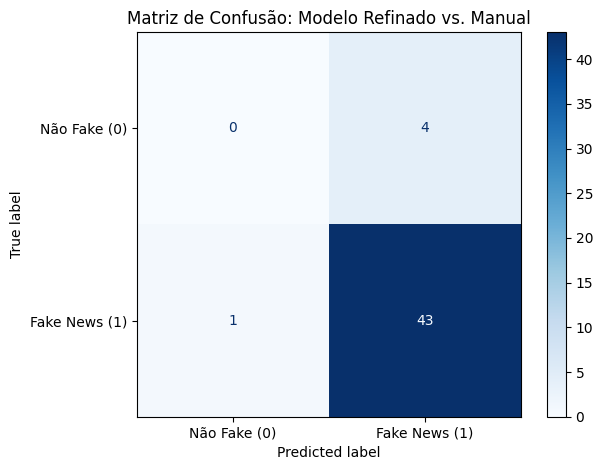

In [72]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# --- Seus Dados (Exemplo - Substitua pelos seus) ---
# Suponha que Y_manual e preds_refinado já existem
# --- Fim dos Seus Dados ---

# Nomes das classes
class_names = ['Não Fake (0)', 'Fake News (1)']

# Calcular a matriz
cm_refinado = confusion_matrix(truth_labels, existing_labels)

# Criar o objeto de display
disp = ConfusionMatrixDisplay(confusion_matrix=cm_refinado, display_labels=class_names)

# Plotar (ele cria a figura internamente)
disp.plot(cmap=plt.cm.Blues, values_format='d') # cmap muda a cor, values_format 'd' para inteiros

# Adicionar um título (opcional, pode ajustar)
plt.title('Matriz de Confusão: Modelo Refinado vs. Manual')

# Ajustar o layout para evitar sobreposição (opcional)
plt.tight_layout() # Tenta ajustar automaticamente

# Salvar a figura (IMPORTANTE!)
#plt.savefig('matriz_confusao_refinado_sklearn.png', dpi=300, bbox_inches='tight')

# Mostrar o gráfico (opcional)
plt.show()

In [167]:
disagreement_df

,id,text,label_snorkel,truth_label
id,,,,
1579249224050671617,1579249224050671617,ameaca stf bolsonaro alem nunca ter apresentad...,1,0
1579250066090766336,1579250066090766336,deve lula governou pais 2x qdo propuseram ter ...,1,0
1579126885992517633,1579126885992517633,quero ver lula ruas versao belo horizonte agor...,0,1
1579260275101814784,1579260275101814784,fake marcola pcc apoia lula verdade assassinos...,1,0
1579251530875949056,1579251530875949056,canibalismo chico buarque bonner tomam foco di...,1,0


In [31]:
df_low_confidence = pd.read_csv('/home/kaka/tcc/ml/data/low_confidence_ml.csv')

In [32]:
L_train = applier.apply(df=df_low_confidence)

  0%|          | 0/3513 [00:00<?, ?it/s]

100%|██████████| 3513/3513 [00:00<00:00, 3845.90it/s]


In [325]:
from sklearn.model_selection import train_test_split

L_train_filtered, L_test_filtered = train_test_split(
    L_train, test_size=0.2, random_state=42)
print(f"Conjunto de treino: {L_train_filtered.shape}")
print(f"Conjunto de teste: {L_test_filtered.shape}")

Conjunto de treino: (2810, 16)
Conjunto de teste: (703, 16)


In [317]:
Y_dev = np.array([None] * L_train_filtered.shape[0])

In [37]:
import numpy as np
import pandas as pd
from snorkel.labeling.model import LabelModel
from sklearn.metrics import classification_report
import joblib


# Y_test = df_test['label']
# print(f"Tamanho L_train: {L_train_filtered.shape}")
# print(f"Tamanho L_test: {L_test_filtered.shape}")
# print(f"Tamanho Y_test: {Y_test.shape}")


# Carregar os RÓTULOS MANUAIS 
print("Carregando rótulos manuais...")
manual_labels_map = {}
indices_with_manual_labels = []
try:
    manual_labels_df = pd.read_csv('data/final_labels.csv').query('is_ground_truth == True')
    manual_labels_map = pd.Series(manual_labels_df.label.values,
                                  index=manual_labels_df.index).to_dict()
    indices_with_manual_labels = list(manual_labels_map.keys())
    print(f"Carregados {len(manual_labels_map)} rótulos manuais.")
except FileNotFoundError:
    print("AVISO: Arquivo 'final_labels.csv' não encontrado. Re-treino será feito sem labels manuais.")
except Exception as e:
    print(f"Erro ao carregar rótulos manuais: {e}")


Carregando rótulos manuais...
Carregados 48 rótulos manuais.


In [38]:
valid_indices = []
valid_labels = []

for idx, manual_label in manual_labels_map.items():
    if 0 <= idx < L_train_filtered.shape[0]:
        valid_indices.append(idx)
        valid_labels.append(manual_label)

# Criar subconjuntos apenas com dados rotulados manualmente
L_train_subset = L_train_filtered[valid_indices]
Y_dev_subset = np.array(valid_labels)

print(f"Subconjunto criado com {len(valid_indices)} amostras rotuladas manualmente.")


In [39]:
valid_indices = []
valid_labels = []

for idx, manual_label in manual_labels_map.items():
    if 0 <= idx < L_train.shape[0]:
        valid_indices.append(idx)
        valid_labels.append(manual_label)

# Criar subconjuntos apenas com dados rotulados manualmente
L_train_subset = L_train[valid_indices]
Y_dev_subset = np.array(valid_labels)

print(f"Subconjunto criado com {len(valid_indices)} amostras rotuladas manualmente.")


Subconjunto criado com 48 amostras rotuladas manualmente.


In [328]:

# Treinar usando apenas o subconjunto para L_train e Y_dev
refined_model = LabelModel(cardinality=2, verbose=True)
refined_model.fit(
    L_train=L_train_subset,  # Apenas as amostras com rótulos manuais
    Y_dev=Y_dev_subset,      # Seus rótulos correspondentes
    n_epochs=500,
    lr=0.01,
    l2=0.1,
    seed=123
)


INFO:root:Computing O...
INFO:root:Estimating \mu...
  0%|          | 0/500 [00:00<?, ?epoch/s]INFO:root:[0 epochs]: TRAIN:[loss=0.111]
INFO:root:[10 epochs]: TRAIN:[loss=0.044]
INFO:root:[20 epochs]: TRAIN:[loss=0.040]
INFO:root:[30 epochs]: TRAIN:[loss=0.037]
INFO:root:[40 epochs]: TRAIN:[loss=0.039]
INFO:root:[50 epochs]: TRAIN:[loss=0.037]
 11%|█         | 55/500 [00:00<00:00, 544.57epoch/s]INFO:root:[60 epochs]: TRAIN:[loss=0.037]
INFO:root:[70 epochs]: TRAIN:[loss=0.037]
INFO:root:[80 epochs]: TRAIN:[loss=0.037]
INFO:root:[90 epochs]: TRAIN:[loss=0.037]
INFO:root:[100 epochs]: TRAIN:[loss=0.037]
INFO:root:[110 epochs]: TRAIN:[loss=0.037]
INFO:root:[120 epochs]: TRAIN:[loss=0.037]
 24%|██▍       | 122/500 [00:00<00:00, 607.65epoch/s]INFO:root:[130 epochs]: TRAIN:[loss=0.037]
INFO:root:[140 epochs]: TRAIN:[loss=0.037]
INFO:root:[150 epochs]: TRAIN:[loss=0.037]
INFO:root:[160 epochs]: TRAIN:[loss=0.037]
INFO:root:[170 epochs]: TRAIN:[loss=0.037]
INFO:root:[180 epochs]: TRAIN:[loss=0

In [329]:

# Para predições, use o conjunto completo
test_preds = refined_model.predict(L=L_test_filtered)

In [ ]:
# Avalie o modelo refinado no conjunto de teste
refined_preds = refined_model.predict(L=L_test_filtered)
refined_probs = refined_model.predict_proba(L=L_test_filtered)



print("\n=== Análise Básica do Modelo Refinado ===")
print(f"Distribuição de classes previstas: {np.bincount(refined_preds)}")
print(f"Confiança média (máx. probabilidade): {np.mean(np.max(refined_probs, axis=1)):.4f}")



=== Análise Básica do Modelo Refinado ===
Distribuição de classes previstas: [  0 703]
Confiança média (máx. probabilidade): 0.9630


In [375]:
# Avaliar em dados de teste (se tiver ground truth)
test_preds = refined_model.predict(L=L_test_filtered)
test_probs = refined_model.predict_proba(L=L_test_filtered)

# Analisar confiança
baseline_conf = np.max(label_model.predict_proba(L=L_test_filtered), axis=1)
refined_conf = np.max(test_probs, axis=1)
print(f"Confiança média (baseline): {baseline_conf.mean() * 100:.1f}%")
print(f"Confiança média (refinado): {refined_conf.mean() * 100:.1f}%")

# Transformar para porcentagem:
baseline_conf_percentage = baseline_conf * 100
refined_conf_percentage = refined_conf * 100



Confiança média (baseline): 78.5%
Confiança média (refinado): 96.3%


Total de exemplos: 31
Exemplos de baixa confiança: 0 (0.00%)
Exemplos de média confiança: 1 (3.23%)
Exemplos de alta confiança: 30 (96.77%)
Gráfico de distribuição de confiança salvo como 'confidence_distribution_retrain.png'


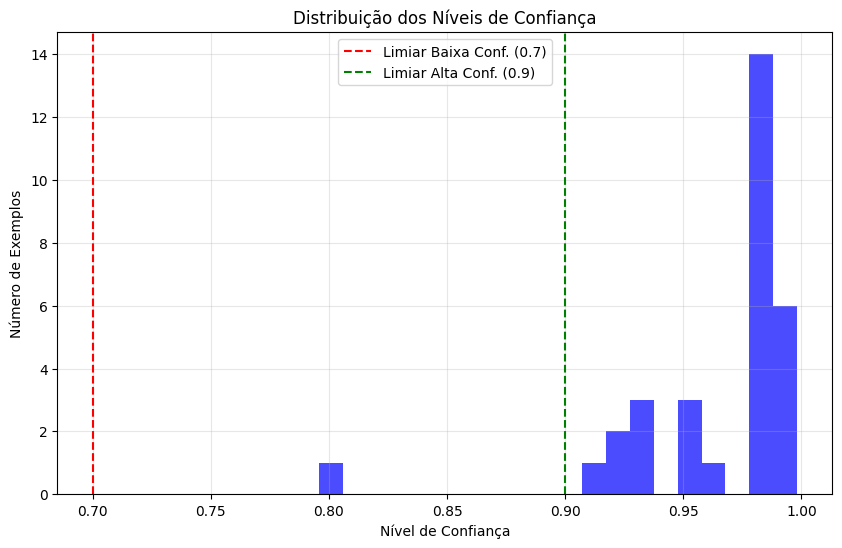

In [378]:
import numpy as np

# 1. Obter as probabilidades para todos os exemplos
probas = refined_model.predict_proba(L=L_train_subset)

# 2. Calcular a confiança (valor da maior probabilidade)
# Isso funciona para qualquer número de classes
confidences = np.max(probas, axis=1)

# 3. Definir seus limiares
low_confidence_threshold = 0.7   # Exemplos abaixo disso são de "baixa confiança"
high_confidence_threshold = 0.9  # Exemplos acima disso são de "alta confiança"

# 4. Filtrar exemplos por confiança
low_confidence_indices = np.where(confidences < low_confidence_threshold)[0]
high_confidence_indices = np.where(confidences >= high_confidence_threshold)[0]
medium_confidence_indices = np.where((confidences >= low_confidence_threshold) & 
                                    (confidences < high_confidence_threshold))[0]

# 5. Imprimir estatísticas
print(f"Total de exemplos: {len(confidences)}")
print(f"Exemplos de baixa confiança: {len(low_confidence_indices)} ({len(low_confidence_indices)/len(confidences):.2%})")
print(f"Exemplos de média confiança: {len(medium_confidence_indices)} ({len(medium_confidence_indices)/len(confidences):.2%})")
print(f"Exemplos de alta confiança: {len(high_confidence_indices)} ({len(high_confidence_indices)/len(confidences):.2%})")


# 7. Bônus: Visualizar a distribuição de confiança
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.hist(confidences, bins=20, alpha=0.7, color='blue')
plt.axvline(x=low_confidence_threshold, color='r', linestyle='--', label=f'Limiar Baixa Conf. ({low_confidence_threshold})')
plt.axvline(x=high_confidence_threshold, color='g', linestyle='--', label=f'Limiar Alta Conf. ({high_confidence_threshold})')
plt.xlabel('Nível de Confiança')
plt.ylabel('Número de Exemplos')
plt.title('Distribuição dos Níveis de Confiança')
plt.legend()
plt.grid(alpha=0.3)
plt.savefig('confidence_distribution_retrain.png')
print("Gráfico de distribuição de confiança salvo como 'confidence_distribution_retrain.png'")


### Analyzing tags obtained from users

In [288]:
gt = ground_truth_df['tags'].drop_duplicates()
gt = gt.dropna()

In [289]:
# transform tags into a list 
gt = gt.apply(lambda x: x.split(','))
gt = gt.explode()

In [290]:
tags = set(gt)

In [291]:
tags = list(tags)
# get lower case
tags = [tag.strip() for tag in tags]
tags = [tag.lower() for tag in tags]
tags = list(set(tags))

In [292]:
len(tags)

55

In [293]:
tags

['neto',
 'satânico',
 'oposição',
 'internacional',
 'ditatoriais',
 'ameaçando',
 'contra',
 'zema',
 'bolsoaro',
 'jairbolsonaro',
 'minas',
 'reportagem',
 'destrói',
 'the guardian',
 'ameça',
 'minas gerais',
 'ameaça',
 'mineiro',
 '9 dedos',
 'proibiu',
 'abortista',
 'ministro',
 'brasil',
 'satanico',
 'corrupto',
 'estado',
 'ex-presidiário',
 'ameaçar',
 'tse',
 'cachaceiro',
 'aborto',
 'nine',
 'erro',
 'canibalismo',
 'verba',
 'noticia verdadeira',
 'romeu zema',
 'canibal',
 'mídia',
 'interessante',
 'humana',
 'ameaçou',
 'lula',
 'bolsonaro',
 'rouanet',
 'federal',
 'carne',
 'governador',
 'jair',
 'comunismo',
 'miriam cordeiro',
 'presidente',
 'sem provas',
 'mg',
 'stf']

In [297]:
canibal_keywords = ['canibal', 'canibalismo', 'carne humana']
maconaria_keywords = ['maconaria', 'macom', 'seita']
satanismo_keywords = ['satanismo', 'satanista', 'satanico','baphomet']
censura_keywords = ['censura', 'censurar', 'censurado']
pcc_keywords = ['pcc', 'marcola']
ameaca_keywords = ['ameaca', 'ameacar', 'ameacado', 'ameacando', 'ameacou']
aborto_keywords = ['aborto', 'abortar', 'abortista']
comunismo_keywords = ['comunismo', 'comunista', 'mst']
taxacao_keywords = ['taxacao', 'taxar', 'taxado', 'taxando', 'taxou']
lula_keywords = ['nine', '9 dedos', 'cachaceiro']
pedofilia_keywords = ['pedofilia', 'pedofilo', 'pedofilos'] 
others_keywords = ['zema', 'rouanet', 'ladrao', 'pedofilia', 'fraude', 'urna', 'urnas']

# look for tags who aren't in the lists above:
tags = set(tags) - set(canibal_keywords) - set(satanismo_keywords) - set(maconaria_keywords) - set(censura_keywords) - set(pcc_keywords) - set(ameaca_keywords) - set(aborto_keywords) - set(comunismo_keywords) - set(taxacao_keywords) - set(lula_keywords) - set(pedofilia_keywords) - set(others_keywords)
tags = list(tags)

print(tags)

['neto', 'satânico', 'oposição', 'internacional', 'ditatoriais', 'ameaçando', 'contra', 'mg', 'bolsoaro', 'jairbolsonaro', 'minas', 'reportagem', 'destrói', 'the guardian', 'ameça', 'minas gerais', 'ameaça', 'mineiro', 'proibiu', 'brasil', 'corrupto', 'estado', 'ex-presidiário', 'ameaçar', 'tse', 'erro', 'verba', 'noticia verdadeira', 'romeu zema', 'mídia', 'interessante', 'humana', 'ameaçou', 'lula', 'bolsonaro', 'federal', 'carne', 'governador', 'jair', 'miriam cordeiro', 'presidente', 'sem provas', 'ministro', 'stf']


In [298]:
len(tags)


44

In [299]:
tags

['neto',
 'satânico',
 'oposição',
 'internacional',
 'ditatoriais',
 'ameaçando',
 'contra',
 'mg',
 'bolsoaro',
 'jairbolsonaro',
 'minas',
 'reportagem',
 'destrói',
 'the guardian',
 'ameça',
 'minas gerais',
 'ameaça',
 'mineiro',
 'proibiu',
 'brasil',
 'corrupto',
 'estado',
 'ex-presidiário',
 'ameaçar',
 'tse',
 'erro',
 'verba',
 'noticia verdadeira',
 'romeu zema',
 'mídia',
 'interessante',
 'humana',
 'ameaçou',
 'lula',
 'bolsonaro',
 'federal',
 'carne',
 'governador',
 'jair',
 'miriam cordeiro',
 'presidente',
 'sem provas',
 'ministro',
 'stf']

In [40]:
from snorkel.labeling.model import LabelModel
import numpy as np

# Suponha que você tenha:
# L_full_train: Matriz de LFs para todos os 5438 exemplos rotulados pelo Snorkel (5438, num_LFs)
# indices_manual: Os índices (dentro de L_full_train) dos 48 exemplos rotulados manualmente
# Y_manual: O array numpy com os 48 rótulos manuais (0 ou 1) (48,)


# 3. Re-treinamento do LabelModel Refinado
label_model_refinado = LabelModel(cardinality=2, verbose=True)

# Fornecer L_train (grande), L_dev (pequeno), e Y_dev (pequeno)
label_model_refinado.fit(L_train=L_train, # Usa todos os votos para aprender relações
                         Y_dev=Y_dev_subset,      # Rótulos manuais para ancorar precisões
                         n_epochs=100,
                         log_freq=20,
                         seed=123)

# Agora label_model_refinado aprendeu tanto das relações gerais (L_train)
# quanto da verdade específica (L_dev, Y_dev).


INFO:root:Computing O...
INFO:root:Estimating \mu...
  0%|          | 0/100 [00:00<?, ?epoch/s]INFO:root:[0 epochs]: TRAIN:[loss=0.086]
INFO:root:[20 epochs]: TRAIN:[loss=0.027]
INFO:root:[40 epochs]: TRAIN:[loss=0.021]
 54%|█████▍    | 54/100 [00:00<00:00, 533.68epoch/s]INFO:root:[60 epochs]: TRAIN:[loss=0.020]
INFO:root:[80 epochs]: TRAIN:[loss=0.020]
100%|██████████| 100/100 [00:00<00:00, 635.24epoch/s]
INFO:root:Finished Training


In [43]:
LFAnalysis(L=L_train, lfs=lfs).lf_summary()


,j,Polarity,Coverage,Overlaps,Conflicts
keyword_canibal,0,[1],0.079135,0.023911,0.002562
keyword_maconaria,1,[1],0.025619,0.009678,0.000285
keyword_satanismo,2,[1],0.024765,0.011671,0.000285
keyword_censura,3,[1],0.031312,0.008824,0.000854
keyword_pcc,4,[1],0.049246,0.012525,0.000285
keyword_ameaca,5,[1],0.143182,0.095645,0.001423
keyword_zema,6,[1],0.099061,0.099061,0.001423
lf_rouanet,7,[1],0.036721,0.002847,0.000285
keyword_aborto,8,[1],0.039283,0.013379,0.001139
keyword_declaracao_voto,9,[0],0.014518,0.014518,0.014518


In [ ]:
acc = LFAnalysis(L=L_train_subset, lfs=lfs).lf_empirical_accuracies(Y_dev_subset)
acc

array([0.9   , 1.    , 1.    , 0.    , 0.5   , 0.9375, 1.    , 1.    ,
       1.    , 0.    , 1.    , 0.    , 0.    , 0.    , 1.    , 1.    ])

In [60]:
from snorkel.analysis import metric_score

# Calcular a precisão, recall e F1-score
accuracy = metric_score(Y_dev_subset, label_model_refinado.predict(L=L_train_subset), metric='accuracy')
precision = metric_score(Y_dev_subset, label_model_refinado.predict(L=L_train_subset), metric='precision')
recall = metric_score(Y_dev_subset, label_model_refinado.predict(L=L_train_subset), metric='recall')
f1 = metric_score(Y_dev_subset, label_model_refinado.predict(L=L_train_subset), metric='f1')

print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-score: {f1:.4f}")


Accuracy: 0.9167
Precision: 0.9167
Recall: 1.0000
F1-score: 0.9565


In [66]:
# Avalie o modelo refinado no conjunto de teste
refined_preds = label_model_refinado.predict(L=L_train)
refined_probs = label_model_refinado.predict_proba(L=L_train)



print("\n=== Análise Básica do Modelo Refinado ===")
print(f"Confiança média (máx. probabilidade): {np.mean(np.max(refined_probs, axis=1))*100 :.2f}%")


=== Análise Básica do Modelo Refinado ===
Confiança média (máx. probabilidade): 97.79%


In [ ]:
import 

print("Matriz de Confusão (Refinado vs Manual):")
# Lembre-se: linhas=True, colunas=Predicted
cm_refinado = confusion_matrix(Y_manual, refined_preds) 
print(cm_refinado)

In [68]:
from sklearn.metrics import confusion_matrix, classification_report

print("Matriz de Confusão (Refinado vs Manual):")
# Lembre-se: linhas=True, colunas=Predicted
cm_refinado = confusion_matrix(Y_dev_subset, refined_preds) 
print(cm_refinado) 
# Extraia TN_ref, FP_ref, FN_ref, TP_ref daqui

print("\nMétricas de Classificação (Modelo Refinado):")
report_refinado = classification_report(Y_dev_subset, refined_preds, output_dict=True)
print(classification_report(Y_dev_subset, refined_preds)) 

# Extraia os valores para a tabela:
acc_ref = report_refinado['accuracy']
prec_ref = report_refinado['1']['precision'] # Precisão da classe 1
rec_ref = report_refinado['1']['recall']    # Recall da classe 1
f1_ref = report_refinado['1']['f1-score']  # F1 da classe 1

In [7]:
import pandas as pd 

# LER ARQUVIO JSON
df = pd.read_csv('data/low_confidence_ml.csv')

## Table 5 

Realizar dois experimentos: 
1) Trained model using only data labeled with Labeling Functions without human intervention
2) Trained model using data labeled with Labeling Functions and human intervention

Use the same test data for both experiments.


In [1]:
import pandas as pd
low_confidence_df = pd.read_csv('data/low_confidence_ml.csv')
tweets_rotulados_df = pd.read_csv('data/tweets_rotulados/tweets_rotulados_normalizados.csv')

In [2]:
tweets_rotulados_df.rename(columns={'tweet_id': 'id'}, inplace=True)

In [3]:
low_confidence_with_ground_truth = low_confidence_df.copy()

# Manter apenas as colunas 'id', 'text' e 'label'
tweets_rotulados_df = tweets_rotulados_df[['id', 'text', 'label']]

In [4]:
# replace the label of low_confidence_df with the label of tweets_rotulados_df based on the id
low_confidence_with_ground_truth = low_confidence_with_ground_truth.merge(tweets_rotulados_df, on='id', how='left', suffixes=('', '_ground_truth'))

In [5]:
low_confidence_with_ground_truth['label'] = low_confidence_with_ground_truth['label'].astype(float)

In [6]:
low_confidence_with_ground_truth = low_confidence_with_ground_truth[['id', 'text', 'label', 'label_ground_truth']]

In [7]:
# replace the label from the label_ground_truth if are different and not null 

low_confidence_with_ground_truth['label'] = low_confidence_with_ground_truth.apply(
    lambda row: row['label_ground_truth'] if row['label'] != row['label_ground_truth'] and pd.notnull(row['label_ground_truth']) else row['label'], axis=1
)

In [8]:
# create a new column 'is_ground_truth' to indicate if the label is from the ground truth - True or False
low_confidence_with_ground_truth['is_ground_truth'] = low_confidence_with_ground_truth.apply(
    lambda row: True if pd.notnull(row['label_ground_truth']) else False, axis=1
)

In [9]:
low_confidence_with_ground_truth = low_confidence_with_ground_truth[['id', 'text', 'label', 'is_ground_truth']]

In [10]:
from sklearn.model_selection import train_test_split

train_df_low_confidence_gt, test_df_low_confidence_gt = train_test_split(low_confidence_with_ground_truth, test_size=0.2, random_state=42)

In [11]:
# use the same test set for the model without ground truth

train_df_low_confidence, test_df_low_confidence = train_test_split(low_confidence_df, test_size=0.2, random_state=42)

In [34]:
# remove tweets_rotulados id from train_df_low_confidence
train_df_low_confidence = train_df_low_confidence[~train_df_low_confidence['id'].isin(tweets_rotulados_df['id'])]

In [105]:
df_unlabeled_filtered = df_unlabeled_filtered[~df_unlabeled_filtered['id'].isin(tweets_rotulados_df['id'])]

In [12]:
test_df = test_df_low_confidence[~test_df_low_confidence['id'].isin(train_df_low_confidence['id']) 
                                                      & ~test_df_low_confidence['id'].isin(train_df_low_confidence_gt['id'])]

Nos dois experimentos, o modelo foi treinado com 80% dos dados rotulados e testado com 20% dos dados rotulados.
Temos dois datasets de treino (train_df_low_confidence e train_df_low_confidence_gt) um dataset de teste (test_df_low_confidence_gt).


In [106]:
#train_df_low_confidence = train_df_low_confidence[['id', 'text', 'label']]
df_unlabeled_filtered = df_unlabeled_filtered[['id', 'text', 'label']]
test_df = test_df_low_confidence[['id', 'text', 'label']]
train_df_low_confidence_gt = train_df_low_confidence_gt[['id', 'text', 'label']]

In [107]:
L_train_inital_model = applier.apply(df=df_unlabeled_filtered)
L_train_low_confidence_gt = applier.apply(df=train_df_low_confidence_gt) # with ground truth
L_test = applier.apply(df=test_df)

100%|██████████| 703/703 [00:00<00:00, 3808.31it/s]


In [108]:
from snorkel.labeling.model import LabelModel

label_model_lc = LabelModel(cardinality=2, verbose=True)
label_model_lc.fit(L_train_inital_model, n_epochs=65, log_freq=10, seed=123)

INFO:root:Computing O...
INFO:root:Estimating \mu...
  0%|          | 0/65 [00:00<?, ?epoch/s]INFO:root:[0 epochs]: TRAIN:[loss=0.070]
INFO:root:[10 epochs]: TRAIN:[loss=0.034]
INFO:root:[20 epochs]: TRAIN:[loss=0.020]
INFO:root:[30 epochs]: TRAIN:[loss=0.020]
INFO:root:[40 epochs]: TRAIN:[loss=0.017]
 74%|███████▍  | 48/65 [00:00<00:00, 478.62epoch/s]INFO:root:[50 epochs]: TRAIN:[loss=0.016]
INFO:root:[60 epochs]: TRAIN:[loss=0.015]
100%|██████████| 65/65 [00:00<00:00, 489.85epoch/s]
INFO:root:Finished Training


In [38]:
from snorkel.labeling.model import LabelModel

label_model_lc_gt = LabelModel(cardinality=2, verbose=True)
label_model_lc_gt.fit(L_train_low_confidence_gt, n_epochs=65, log_freq=10, seed=123)

INFO:root:Computing O...
INFO:root:Estimating \mu...
  0%|          | 0/65 [00:00<?, ?epoch/s]INFO:root:[0 epochs]: TRAIN:[loss=0.085]
INFO:root:[10 epochs]: TRAIN:[loss=0.044]
INFO:root:[20 epochs]: TRAIN:[loss=0.026]
INFO:root:[30 epochs]: TRAIN:[loss=0.025]
INFO:root:[40 epochs]: TRAIN:[loss=0.022]
INFO:root:[50 epochs]: TRAIN:[loss=0.021]
INFO:root:[60 epochs]: TRAIN:[loss=0.020]
100%|██████████| 65/65 [00:00<00:00, 739.11epoch/s]
INFO:root:Finished Training


In [39]:
Y_test = test_df['label']

Accuracy: 0.9929
Precision: 0.9943
Recall: 0.9986
F1-score: 0.9964
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         4
           1       0.99      1.00      1.00       699

    accuracy                           0.99       703
   macro avg       0.50      0.50      0.50       703
weighted avg       0.99      0.99      0.99       703

Confusion Matrix:
[[  0   4]
 [  1 698]]


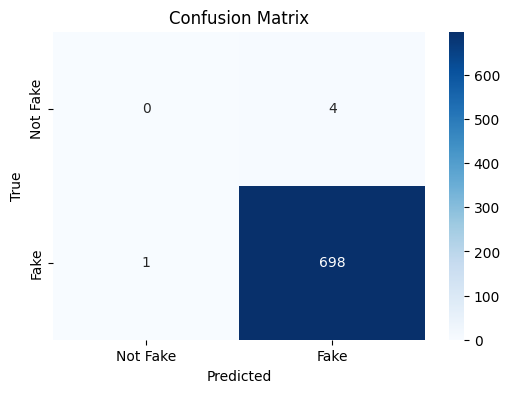

In [111]:
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline

from sklearn.preprocessing import StandardScaler

from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

# Use model without ground truth 
X_train = df_unlabeled_filtered['text']
y_train = df_unlabeled_filtered['label']
X_test = test_df['text']
y_test = test_df['label']

# Create a pipeline with StandardScaler and SVC
model = make_pipeline(TfidfVectorizer(), SVC(probability=True, kernel='linear'))
# Fit the model
model.fit(X_train, y_train)
# Predict on the test set
y_pred = model.predict(X_test)
# Predict probabilities
y_pred_proba = model.predict_proba(X_test)
# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}")
# Calculate precision, recall, f1-score
precision, recall, f1, _ = precision_recall_fscore_support(y_test, y_pred, average='binary')
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-score: {f1:.4f}")
# Print classification report
print(classification_report(y_test, y_pred))
# Print confusion matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))
# Print confusion matrix
import seaborn as sns
import matplotlib.pyplot as plt

# plot confusion matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Not Fake', 'Fake'], yticklabels=['Not Fake', 'Fake'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()


Accuracy: 0.9943
Precision: 0.9943
Recall: 1.0000
F1-score: 0.9971
              precision    recall  f1-score   support

           0       0.00      0.00      0.00         4
           1       0.99      1.00      1.00       699

    accuracy                           0.99       703
   macro avg       0.50      0.50      0.50       703
weighted avg       0.99      0.99      0.99       703

Confusion Matrix:
[[  0   4]
 [  0 699]]


/home/kaka/.local/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/kaka/.local/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/home/kaka/.local/lib/python3.10/site-packages/sklearn/metrics/_classification.py:1531: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


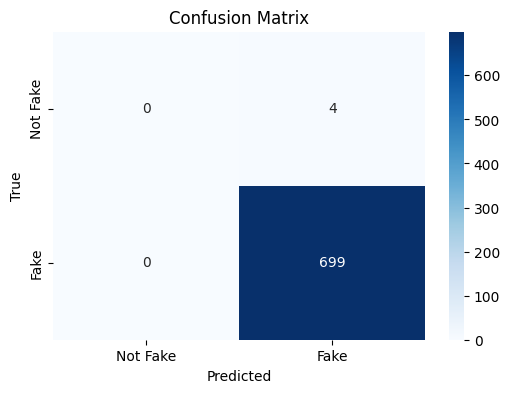

In [112]:
from sklearn.svm import SVC
from sklearn.pipeline import make_pipeline

from sklearn.feature_extraction.text import TfidfVectorizer

from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

# Use model without ground truth 
X_train = train_df_low_confidence_gt['text']
y_train = train_df_low_confidence_gt['label']
X_test = test_df['text']
y_test = test_df['label']

# Create a pipeline with TfidfVectorizer and SVC
model = make_pipeline(TfidfVectorizer(), SVC(probability=True, kernel='linear'))
# Fit the model
model.fit(X_train, y_train)
# Predict on the test set
y_pred = model.predict(X_test)
# Predict probabilities
y_pred_proba = model.predict_proba(X_test)
# Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}")
# Calculate precision, recall, f1-score
precision, recall, f1, _ = precision_recall_fscore_support(y_test, y_pred, average='binary')
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-score: {f1:.4f}")
# Print classification report
print(classification_report(y_test, y_pred))
# Print confusion matrix
print("Confusion Matrix:")
print(confusion_matrix(y_test, y_pred))
# Print confusion matrix
import seaborn as sns
import matplotlib.pyplot as plt

# plot confusion matrix
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Not Fake', 'Fake'], yticklabels=['Not Fake', 'Fake'])
plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()
